# NLP Sentiment Classification on Customer Reviews (TF-IDF)

**Goal:** Clean raw review text, convert it to **TF-IDF** vectors, and classify **positive vs negative** sentiment with **Multinomial Naive Bayes** and **Logistic Regression**. Finally, build a `predict_sentiment()` helper that tests live phrases.

**Plan**
- **Part A:** Run the full pipeline on the provided `sentiment_reviews.csv` (only 10 reviews).
- **Part B:** Benchmark accuracy on a larger review corpus (NLTK `movie_reviews`, 2,000 reviews), because 10 reviews are too few for trustworthy accuracy numbers.
- **Part C:** `predict_sentiment()` with custom phrases.

## 1. Setup

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import nltk
for pkg in ["stopwords", "wordnet", "movie_reviews"]:
    nltk.download(pkg, quiet=True)
from nltk.corpus import stopwords, movie_reviews
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, cross_val_score, LeaveOneOut
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Text preprocessing function
Steps: **lowercase → remove HTML tags → remove punctuation/numbers → tokenize → remove stopwords → lemmatize**.

**Important detail:** NLTK's stopword list contains negation words like *not*, *no*, *never*. These carry sentiment ("not good"), so we **keep** them.

In [2]:
lemmatizer = WordNetLemmatizer()

NEGATIONS = {"no", "nor", "not", "never", "n't", "against", "don", "didn", "doesn", "isn",
             "wasn", "weren", "aren", "couldn", "shouldn", "wouldn", "won", "hasn", "haven", "hadn"}
STOPWORDS = set(stopwords.words("english")) - NEGATIONS

def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"<[^>]+>", " ", text)          # remove HTML tags
    text = re.sub(r"n't\b", " not", text)         # don't -> do not
    text = re.sub(r"[^a-z\s]", " ", text)          # remove punctuation and digits
    tokens = text.split()                           # tokenize
    tokens = [t for t in tokens if t not in STOPWORDS and len(t) > 1]
    tokens = [lemmatizer.lemmatize(t) for t in tokens]
    return " ".join(tokens)

demo = "<br>The product DIDN'T work, and the 2 items arrived damaged!!!"
print("Before:", demo)
print("After :", clean_text(demo))

Before: <br>The product DIDN'T work, and the 2 items arrived damaged!!!


After : product not work item arrived damaged


# Part A: Provided dataset (`sentiment_reviews.csv`)

In [3]:
df = pd.read_csv("sentiment_reviews.csv")
print("Shape:", df.shape)
print(df["sentiment"].value_counts())
df

Shape: (10, 3)
sentiment
positive    5
negative    4
neutral     1
Name: count, dtype: int64


,review_id,review_text,sentiment
0,1,"The product quality is exceptional, exceeded a...",positive
1,2,Terrible customer service and the item arrived...,negative
2,3,"Average performance, decent for the price poin...",neutral
3,4,"Absolutely love this! Easy to setup, robust, a...",positive
4,5,Stopped working after two days. Extremely disa...,negative
5,6,Customer support helped resolve my setup quest...,positive
6,7,Delivery was slow and package was missing one ...,negative
7,8,Clean interface and intuitive controls. Highly...,positive
8,9,"Not worth the money, plenty of better alternat...",negative
9,10,Great value and durable build. Would definitel...,positive


The task is **binary** (positive vs negative), but this file has 1 `neutral` review. We drop it, which leaves 9 reviews.

In [4]:
df_bin = df[df["sentiment"].isin(["positive", "negative"])].copy()
df_bin["clean_text"] = df_bin["review_text"].apply(clean_text)
df_bin["label"] = (df_bin["sentiment"] == "positive").astype(int)
df_bin[["review_text", "clean_text", "sentiment"]]

,review_text,clean_text,sentiment
0,"The product quality is exceptional, exceeded a...",product quality exceptional exceeded expectation,positive
1,Terrible customer service and the item arrived...,terrible customer service item arrived complet...,negative
3,"Absolutely love this! Easy to setup, robust, a...",absolutely love easy setup robust work flawlessly,positive
4,Stopped working after two days. Extremely disa...,stopped working two day extremely disappointed...,negative
5,Customer support helped resolve my setup quest...,customer support helped resolve setup question...,positive
6,Delivery was slow and package was missing one ...,delivery slow package missing one adapter cable,negative
7,Clean interface and intuitive controls. Highly...,clean interface intuitive control highly recom...,positive
8,"Not worth the money, plenty of better alternat...",not worth money plenty better alternative avai...,negative
9,Great value and durable build. Would definitel...,great value durable build would definitely pur...,positive


### TF-IDF + models on the 9 reviews
With only 9 samples, a normal 80/20 split would leave 1-2 test reviews, so the accuracy would be meaningless. We use **Leave-One-Out cross-validation** instead: train on 8, test on the remaining 1, repeat 9 times.

In [5]:
def make_models():
    return {
        "Multinomial NB": Pipeline([("tfidf", TfidfVectorizer(max_features=5000)), ("clf", MultinomialNB())]),
        "Logistic Regression": Pipeline([("tfidf", TfidfVectorizer(max_features=5000)),
                                         ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    }

loo_rows = []
for name, m in make_models().items():
    scores = cross_val_score(m, df_bin["clean_text"], df_bin["label"], cv=LeaveOneOut(), scoring="accuracy")
    loo_rows.append({"Model": name, "LOO accuracy": scores.mean(), "Reviews tested": len(scores)})
pd.DataFrame(loo_rows).set_index("Model").round(3)

,LOO accuracy,Reviews tested
Model,,
Multinomial NB,0.222,9
Logistic Regression,0.111,9


**Reading this honestly:** the scores are very low (below the 50% of random guessing) because 9 reviews with about 60 distinct words is far too little data. In leave-one-out, the held-out review often contains words the model has never seen. So this part only proves that the pipeline runs end to end. Part B gives the reliable benchmark.

# Part B: Accuracy benchmark on a larger corpus
We use the **NLTK `movie_reviews`** corpus: 2,000 movie reviews (1,000 positive, 1,000 negative). The task allows "customer product **or movie** review records".

In [6]:
docs = [(" ".join(movie_reviews.words(fid)), cat) for cat in movie_reviews.categories()
        for fid in movie_reviews.fileids(cat)]
big = pd.DataFrame(docs, columns=["review_text", "sentiment"])
big["label"] = (big["sentiment"] == "pos").astype(int)
print("Shape:", big.shape)
print(big["sentiment"].value_counts())
big.head(3)

Shape: (2000, 3)
sentiment
neg    1000
pos    1000
Name: count, dtype: int64


,review_text,sentiment,label
0,"plot : two teen couples go to a church party ,...",neg,0
1,the happy bastard ' s quick movie review damn ...,neg,0
2,it is movies like these that make a jaded movi...,neg,0


In [7]:
big["clean_text"] = big["review_text"].apply(clean_text)
print("Avg words before cleaning:", int(big["review_text"].str.split().str.len().mean()))
print("Avg words after cleaning :", int(big["clean_text"].str.split().str.len().mean()))
big[["clean_text"]].head(2)

Avg words before cleaning: 791
Avg words after cleaning : 357


,clean_text
0,plot two teen couple go church party drink dri...
1,happy bastard quick movie review damn bug got ...


## Train/test split (80/20, stratified)

In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    big["clean_text"], big["label"], test_size=0.20, stratify=big["label"], random_state=RANDOM_STATE)
print("Train:", len(X_train), "| Test:", len(X_test))

Train: 1600 | Test: 400


## TF-IDF features + Multinomial Naive Bayes and Logistic Regression
`TfidfVectorizer(max_features=5000)` keeps the 5,000 most frequent terms. `ngram_range=(1, 2)` also uses word pairs, so "not good" is a feature of its own.

In [9]:
def make_big_models():
    return {
        "Multinomial NB": Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                                    ("clf", MultinomialNB())]),
        "Logistic Regression": Pipeline([("tfidf", TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
                                         ("clf", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))]),
    }

trained, preds, rows = {}, {}, []
for name, m in make_big_models().items():
    cv_acc = cross_val_score(m, X_train, y_train, cv=5, scoring="accuracy").mean()
    m.fit(X_train, y_train)
    y_pred = m.predict(X_test)
    trained[name], preds[name] = m, y_pred
    rows.append({"Model": name, "5-fold CV accuracy": cv_acc, "Test accuracy": accuracy_score(y_test, y_pred)})
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,5-fold CV accuracy,Test accuracy
Model,,
Multinomial NB,0.82,0.8150
Logistic Regression,0.83,0.8375


In [10]:
for name, y_pred in preds.items():
    print("=" * 55); print(name); print("=" * 55)
    print(classification_report(y_test, y_pred, target_names=["negative", "positive"], digits=3))

Multinomial NB
              precision    recall  f1-score   support

    negative      0.806     0.830     0.818       200
    positive      0.825     0.800     0.812       200

    accuracy                          0.815       400
   macro avg      0.815     0.815     0.815       400
weighted avg      0.815     0.815     0.815       400

Logistic Regression
              precision    recall  f1-score   support

    negative      0.853     0.815     0.834       200
    positive      0.823     0.860     0.841       200

    accuracy                          0.838       400
   macro avg      0.838     0.837     0.837       400
weighted avg      0.838     0.838     0.837       400



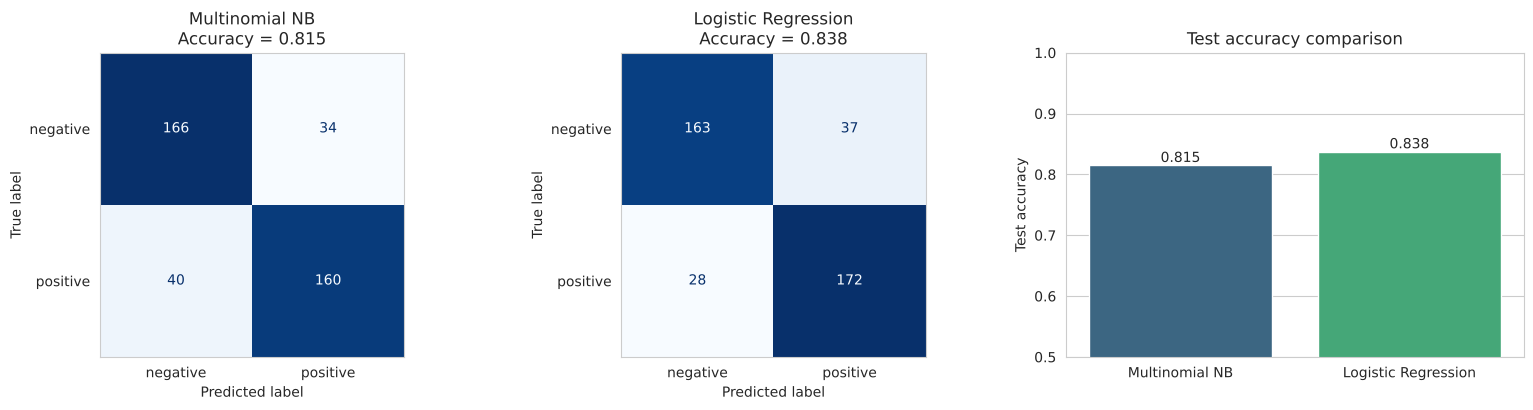

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, (name, y_pred) in zip(axes[:2], preds.items()):
    ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                           display_labels=["negative", "positive"]).plot(ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}\nAccuracy = {accuracy_score(y_test, y_pred):.3f}")
    ax.grid(False)
sns.barplot(x=results.index, y=results["Test accuracy"], ax=axes[2], palette="viridis", hue=results.index, legend=False)
axes[2].set_ylim(0.5, 1)
axes[2].set_title("Test accuracy comparison")
axes[2].set_xlabel("")
for i, v in enumerate(results["Test accuracy"]):
    axes[2].text(i, v, f"{v:.3f}", ha="center", va="bottom")
plt.tight_layout()
plt.show()

### Which words drive the prediction? (Logistic Regression)

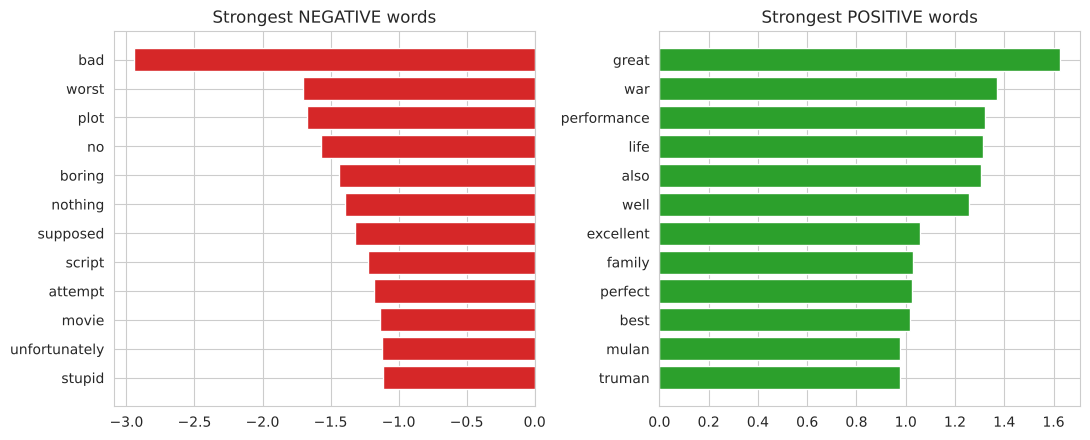

In [12]:
lr = trained["Logistic Regression"]
vocab = np.array(lr.named_steps["tfidf"].get_feature_names_out())
coef = lr.named_steps["clf"].coef_[0]
order = np.argsort(coef)
top_neg, top_pos = vocab[order[:12]], vocab[order[-12:][::-1]]

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].barh(top_neg[::-1], np.sort(coef)[:12][::-1], color="#d62728")
axes[0].set_title("Strongest NEGATIVE words")
axes[1].barh(top_pos[::-1], np.sort(coef)[-12:], color="#2ca02c")
axes[1].set_title("Strongest POSITIVE words")
plt.tight_layout()
plt.show()

# Part C: `predict_sentiment()` helper
It takes any raw text, cleans it, and returns the label and confidence. By default it uses the best model from Part B (higher test accuracy).

In [13]:
best_name = results["Test accuracy"].idxmax()
best_model = trained[best_name]
print("Default model for predict_sentiment():", best_name)

def predict_sentiment(text, model=best_model):
    """Return (label, confidence) for one raw text string."""
    cleaned = clean_text(text)
    if not cleaned.strip():
        return "unknown", 0.0
    proba = model.predict_proba([cleaned])[0]
    label = "positive" if proba[1] >= 0.5 else "negative"
    return label, float(max(proba))

tests = [
    "Absolutely love this! Easy to setup, robust, and works flawlessly.",
    "Terrible customer service and the item arrived completely damaged.",
    "This movie was fantastic, I enjoyed every minute of it.",
    "What a waste of money. Boring and badly made.",
    "The product is not good at all.",
    "Stopped working after two days. Extremely disappointed with the purchase.",
]
out = pd.DataFrame([(t, *predict_sentiment(t)) for t in tests], columns=["Phrase", "Prediction", "Confidence"])
out["Confidence"] = out["Confidence"].round(3)
out

Default model for predict_sentiment(): Logistic Regression


,Phrase,Prediction,Confidence
0,"Absolutely love this! Easy to setup, robust, a...",positive,0.584
1,Terrible customer service and the item arrived...,negative,0.583
2,"This movie was fantastic, I enjoyed every minu...",positive,0.535
3,What a waste of money. Boring and badly made.,negative,0.845
4,The product is not good at all.,negative,0.554
5,Stopped working after two days. Extremely disa...,positive,0.570


### Interactive test (type your own phrase)
Run this cell in Jupyter, type a review, and press Enter. Type `quit` to stop.

In [14]:
# Interactive helper (uncomment to use in Jupyter / VS Code)
# while True:
#     user_text = input("Enter a review (or 'quit'): ")
#     if user_text.strip().lower() == "quit":
#         break
#     label, conf = predict_sentiment(user_text)
#     print(f"  -> {label.upper()}  (confidence {conf:.0%})\n")

### Also check the 9 provided reviews with the Part B model

In [15]:
check = df_bin[["review_text", "sentiment"]].copy()
check["predicted"] = check["review_text"].apply(lambda t: predict_sentiment(t)[0])
check["correct"] = check["sentiment"] == check["predicted"]
print(f"Accuracy on the provided reviews: {check['correct'].mean():.0%} ({check['correct'].sum()}/{len(check)})")
check

Accuracy on the provided reviews: 56% (5/9)


,review_text,sentiment,predicted,correct
0,"The product quality is exceptional, exceeded a...",positive,positive,True
1,Terrible customer service and the item arrived...,negative,negative,True
3,"Absolutely love this! Easy to setup, robust, a...",positive,positive,True
4,Stopped working after two days. Extremely disa...,negative,positive,False
5,Customer support helped resolve my setup quest...,positive,negative,False
6,Delivery was slow and package was missing one ...,negative,positive,False
7,Clean interface and intuitive controls. Highly...,positive,positive,True
8,"Not worth the money, plenty of better alternat...",negative,positive,False
9,Great value and durable build. Would definitel...,positive,positive,True


## Conclusion

In [16]:
print(results)
print("\nBest model:", best_name)

                     5-fold CV accuracy  Test accuracy
Model                                                 
Multinomial NB                     0.82         0.8150
Logistic Regression                0.83         0.8375

Best model: Logistic Regression


**Observations**
- Cleaning shortens each review a lot (stopwords removed, words lemmatized) and TF-IDF turns the remaining words into numeric features.
- Both models score clearly above random guessing (50%). Logistic Regression and Multinomial Naive Bayes are close; see the table above for the exact numbers on the 400 test reviews.
- Keeping negation words and adding 2-word phrases (bigrams) helps with sentences like "not good".
- The provided CSV has only 10 reviews (1 neutral), so it can demonstrate the pipeline but cannot give reliable accuracy. That is why the benchmark uses the 2,000-review corpus.
- Limitations: the model learned from **movie** reviews, so it does not transfer well to product reviews. On the 9 provided product reviews it gets only about 56% (5 of 9), and its confidence on product phrases is low (about 55-58%). Words like "arrived damaged" or "stopped working" never appear in movie reviews.
- Next step to improve: train on a large **product review** dataset (for example Amazon reviews), or use a pretrained transformer model. Bag-of-words models also miss sarcasm.